# 12. FFN 与 SwiGLU

## 一、普通 FFN：非线性特征学习

Attention 主要负责不同 Token 之间的信息交互；FFN（Feed-Forward Network）对每个 Token 的特征独立进行进一步加工，所有 Token 共享同一套参数。Attention 本身已有非线性，FFN 是为了增强非线性特征学习能力。

**为什么需要权重矩阵和激活函数？** 激活函数只对每个数值独立进行变换，不能直接组合不同维度的特征。因此，先通过可学习的权重矩阵生成中间特征，再对其进行非线性变换。例如（省略偏置）：

$$X=[2,3],\qquad W_1=\begin{bmatrix}1&1&-1\\1&-1&1\end{bmatrix}.$$

$$XW_1=[5,-1,1]\quad\xrightarrow{\operatorname{ReLU}}\quad[5,0,1].$$

$W_1$ 将两个输入特征组合为三个中间特征，ReLU 则对组合后的特征进行筛选。如果直接对 $X$ 使用 ReLU，只能得到 $[2,3]$。实际权重由训练学习得到。

如果没有激活函数，多个线性层仍可合并为一个线性层：$XW_1W_2=X(W_1W_2)$，无法直接表示 $y=x_1x_2$ 等非线性关系。因此，FFN 在线性层之间加入激活函数。

$$\boxed{\operatorname{FFN}(X)=\phi(XW_1+b_1)W_2+b_2}$$

| 组成 | 维度变化 | 作用 |
|---|---|---|
| $W_1$：线性层 | $d_{model}\to d_{ff}$ | 升维，学习更多中间特征组合 |
| $\phi$：激活函数 | $d_{ff}\to d_{ff}$ | 对中间特征进行非线性变换 |
| $W_2$：线性层 | $d_{ff}\to d_{model}$ | 重新组合中间特征，恢复维度，便于残差连接 |

原始 Transformer 使用 ReLU，且 $d_{ff}=4d_{model}$，但这不是固定要求。设 $X$ 的形状为 `(B, L, d_model)`，FFN 只改变最后一个维度。

## 二、激活函数有什么区别？

| 函数 | 公式 | 特点 |
|---|---|---|
| ReLU | $\max(0,x)=x\mathbb I(x>0)$ | 负值置零，正值保持不变 |
| GELU | $x\Phi(x)$ | 通过标准正态分布的累积分布函数 $\Phi$ 平滑调节自身 |
| Sigmoid | $\sigma(x)=1/(1+e^{-x})$ | 输出位于 0 和 1 之间 |
| SiLU | $x\sigma(x)$ | 通过自身的 Sigmoid 值平滑调节自身 |

ReLU、GELU 和 SiLU 都可以写成“输入 × 由自身决定的调节系数”，只是调节方式不同。它们都是逐元素非线性变换，而不是归一化，也不会单独学习另一组特征。

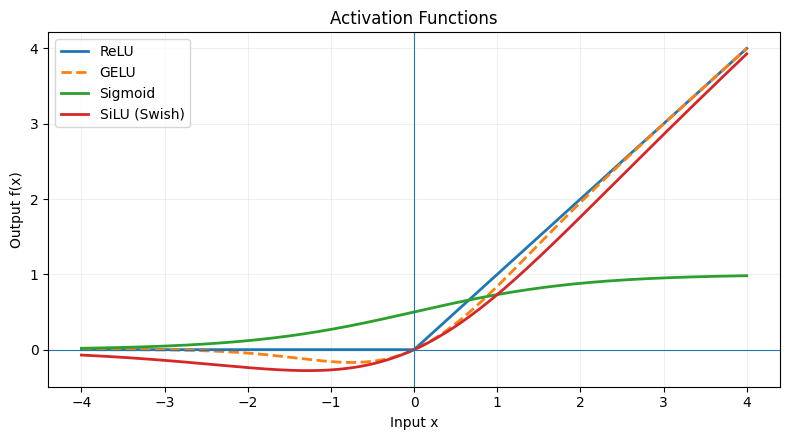

In [1]:
# 激活函数曲线对比
# 对比 FFN 和门控机制中使用的四种激活函数
import numpy as np
import matplotlib.pyplot as plt
from math import erf

# 在 [-4, 4] 内取 401 个输入值
x = np.linspace(-4, 4, 401)

# 根据各自的数学公式计算激活函数的输出
relu = np.maximum(0, x)
# GELU(x) = x * Phi(x)，Phi 为标准正态分布的累积分布函数
gelu = x * 0.5 * (1 + np.vectorize(erf)(x / np.sqrt(2)))
sigmoid = 1 / (1 + np.exp(-x))
silu = x * sigmoid

# 将四种激活函数画在同一张图中，方便比较
plt.figure(figsize=(8, 4.5))
plt.plot(x, relu, label="ReLU", linewidth=2)
plt.plot(x, gelu, label="GELU", linewidth=2, linestyle="--")
plt.plot(x, sigmoid, label="Sigmoid", linewidth=2)
plt.plot(x, silu, label="SiLU (Swish)", linewidth=2)
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.xlabel("Input x")
plt.ylabel("Output f(x)")
plt.title("Activation Functions")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 三、门控 FFN：为什么额外引入一个权重矩阵？

普通 FFN 只有一个中间特征生成分支（以下省略偏置）：

$$A=XW_a,\qquad H=\phi(A).$$

例如 $\operatorname{ReLU}(A)=A\odot\mathbb I(A>0)$，每个中间特征根据自身数值决定如何被调节。GELU、SiLU 直接用于普通 FFN 时也是如此。

另一种设计是将内容生成与门控控制分开：使用两个独立的权重矩阵，从同一个输入学习两组特征，再进行逐元素乘法：

$$\underbrace{A=XW_a}_{\text{内容分支}},\qquad \underbrace{G=XW_g}_{\text{门控分支}},\qquad \boxed{H=A\odot\phi(G)}.$$

**区别在哪里？** 假设内容特征为 $A=x_1+x_2$，门控特征为 $G=x_2-x_1$（两个不同线性投影的示例）：

| 输入 $X$ | 内容 $A$ | 门控 $G$ | 普通 ReLU：$\operatorname{ReLU}(A)$ | 门控 ReLU：$A\cdot\operatorname{ReLU}(G)$ |
|---|---:|---:|---:|---:|
| $[2,0]$ | 2 | -2 | 2 | 0 |
| $[0,2]$ | 2 | 2 | 2 | 4 |

虽然内容特征相同，但门控分支学习了另一种特征组合，可以产生不同的调节结果。**这就是额外引入 $W_g$ 的目的，而不是某种激活函数独有的能力。** 普通 FFN 也可以学习复杂特征关系，门控结构则显式引入两个可学习分支之间的乘法交互。

### 不同门控激活函数：GLU、ReGLU、GEGLU、SwiGLU

门控结构确定后，$\phi$ 可以选择不同的激活函数。两个分支的形状均为 `(B, L, d_ff)`。

| 门控单元 | 中间特征计算 | 门控值的区别 |
|---|---|---|
| GLU | $A\odot\sigma(G)$ | 0～1 之间，只直接衰减或近似保留内容 |
| ReGLU | $A\odot\operatorname{ReLU}(G)$ | 非正门控置零，正门控可放大内容 |
| GEGLU | $A\odot\operatorname{GELU}(G)$ | 平滑门控，可抑制、放大或改变符号 |
| SwiGLU | $A\odot\operatorname{SiLU}(G)$ | 同样是平滑门控，但使用 Sigmoid 而非正态分布的 CDF 调节 $G$ |

注意：**GELU 是激活函数，GEGLU 才是使用 GELU 的门控结构。** ReLU 和 SiLU 也既可以直接用于普通 FFN，又可以用于门控分支。GLU 与其他三个变体的核心结构相同，区别只是门控分支采用的激活函数。

SwiGLU 中的 Swish 通常取 $\beta=1$（即 SiLU）：$\operatorname{SiLU}(G)=G\odot\sigma(G)$，因此 $H=A\odot G\odot\sigma(G)$。选择 SwiGLU 主要基于实验表现，并非数学上必然优于其他变体。参考：[GLU Variants Improve Transformer (2020)](https://arxiv.org/abs/2002.05202)。

## 四、完整的 SwiGLU FFN

SwiGLU 只是生成中间特征的门控单元，还需要一个线性层重新组合中间特征并恢复原始维度：

$$\boxed{Y=[(XW_{\text{up}})\odot\operatorname{SiLU}(XW_{\text{gate}})]W_{\text{down}}}.$$

```text
                  X (B, L, d_model)
                  /                \
            Linear: W_up      Linear: W_gate
                  ↓                ↓
          A (B, L, d_ff)      G (B, L, d_ff)
                  |                ↓ SiLU
                  |              SiLU(G)
                   \              /
                 H = A * SiLU(G)
                         ↓ Linear: W_down
                  Y (B, L, d_model)
```

完整的 SwiGLU FFN 由**三个线性层、一个 SiLU 和一次分支间逐元素乘法**组成。普通 FFN 则由两个线性层与一个激活函数组成。

**为什么常用 $8/3$ 倍升维？** 忽略偏置，普通四倍升维 FFN 有两个权重矩阵，SwiGLU FFN 有三个。为了使参数量相近：

$$2d_{model}(4d_{model})=3d_{model}d_{ff}\quad\Rightarrow\quad d_{ff}=\frac{8}{3}d_{model}.$$

这是参数量对齐时的选择，并不是固定要求，实际模型还可能对中间维度进行取整。